# GPS samples vs reconstructed camera trajectory

Loads the GPS sidecar (`data/1.json`) and the latest reconstruction
(`outputs/ar_run/sfm/sparse`), projects everything back to lat/lon, and
renders both tracks on a single Plotly OpenStreetMap basemap.

- Gray markers + line: raw GPS samples (1 Hz) with 10 m accuracy circles.
- Coloured markers: reconstructed camera centres, frame index → colour.

The JSON has 10 GPS records but lat/lon are quantised to 4 decimal places
(~11 m grid), so several consecutive samples land on the same coordinate.
We fan duplicates out with a sub-metre offset and label each marker with
its 1-indexed sample number so all 10 are visible.


In [8]:
import math
from pathlib import Path

import numpy as np
import plotly.graph_objects as go
import pycolmap

from aivision.gps import EARTH_R, load_track

REPO_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
GPS_JSON = REPO_ROOT / 'data' / '1.json'
RECON_DIR = REPO_ROOT / 'outputs' / 'ar_run' / 'sfm' / 'sparse'
GPS_JSON, RECON_DIR

(PosixPath('/home/misw/Repos/mikemoik/aivision/data/1.json'),
 PosixPath('/home/misw/Repos/mikemoik/aivision/outputs/ar_run/sfm/sparse'))

In [9]:
def enu_to_latlon(enu, origin_lat, origin_lon):
    east, north = enu[:, 0], enu[:, 1]
    lat = origin_lat + np.degrees(north / EARTH_R)
    lon = origin_lon + np.degrees(east / (EARTH_R * math.cos(math.radians(origin_lat))))
    return lat, lon

track = load_track(GPS_JSON)
gps_lat, gps_lon = enu_to_latlon(track.positions_enu, track.origin_lat, track.origin_lon)
print(f'GPS samples: {len(gps_lat)}, mean accuracy: {track.accuracies_m.mean():.1f} m')

rec = pycolmap.Reconstruction(str(RECON_DIR))
img_pairs = sorted(rec.images.items(), key=lambda kv: kv[1].name)
centers_enu = np.stack([
    (-img.cam_from_world().rotation.matrix().T @ img.cam_from_world().translation)
    for _, img in img_pairs
], axis=0)
cam_lat, cam_lon = enu_to_latlon(centers_enu, track.origin_lat, track.origin_lon)
frame_names = [img.name for _, img in img_pairs]
print(f'Reconstructed cameras: {len(cam_lat)}')

GPS samples: 10, mean accuracy: 10.0 m
Reconstructed cameras: 100


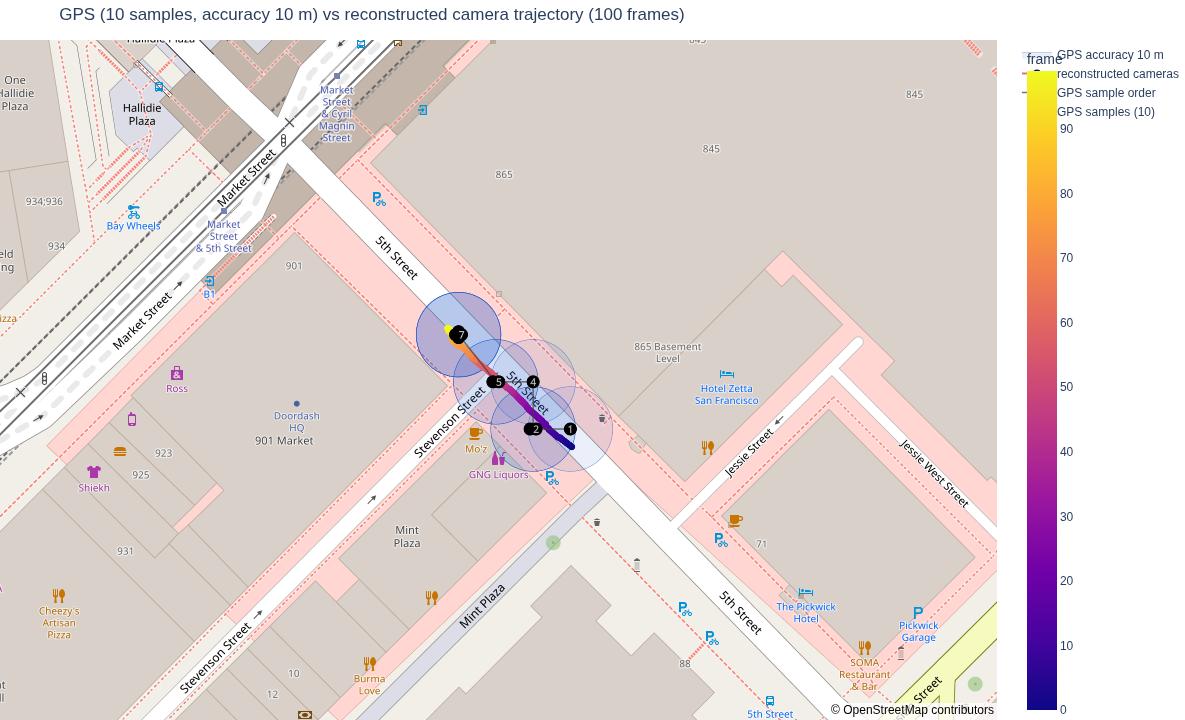

In [10]:
def accuracy_circle(center_lat, center_lon, radius_m, n=60):
    """Geodesic circle as lon/lat points for drawing on the map."""
    angles = np.linspace(0, 2 * np.pi, n)
    deg_per_m_lat = 1.0 / (EARTH_R * math.pi / 180.0)
    deg_per_m_lon = deg_per_m_lat / math.cos(math.radians(center_lat))
    lats = center_lat + radius_m * deg_per_m_lat * np.sin(angles)
    lons = center_lon + radius_m * deg_per_m_lon * np.cos(angles)
    return lats, lons


def fan_duplicates(lats, lons, radius_m=0.7):
    """Spread coincident lat/lon points around a tiny circle so they don't
    stack into a single marker. Deterministic so reruns are stable."""
    lat_center = float(np.mean(lats))
    deg_per_m_lat = 1.0 / (EARTH_R * math.pi / 180.0)
    deg_per_m_lon = deg_per_m_lat / math.cos(math.radians(lat_center))
    out_lat = list(lats.astype(float))
    out_lon = list(lons.astype(float))
    seen: dict[tuple[float, float], list[int]] = {}
    for i, (la, lo) in enumerate(zip(out_lat, out_lon)):
        seen.setdefault((round(la, 6), round(lo, 6)), []).append(i)
    for indices in seen.values():
        if len(indices) <= 1:
            continue
        for k, i in enumerate(indices):
            theta = 2 * math.pi * k / len(indices)
            out_lat[i] += radius_m * deg_per_m_lat * math.sin(theta)
            out_lon[i] += radius_m * deg_per_m_lon * math.cos(theta)
    return np.asarray(out_lat), np.asarray(out_lon)


gps_lat_fan, gps_lon_fan = fan_duplicates(gps_lat, gps_lon, radius_m=0.7)
gps_sample_labels = [str(i + 1) for i in range(len(gps_lat))]

fig = go.Figure()

# Accuracy circles — one filled polygon per (original, un-fanned) GPS sample,
# drawn first so markers sit on top. We use the original positions so the
# circles still cover the reported uncertainty, not the visual fanning.
for i, (lat, lon, acc) in enumerate(zip(gps_lat, gps_lon, track.accuracies_m)):
    c_lat, c_lon = accuracy_circle(lat, lon, acc)
    fig.add_trace(go.Scattermap(
        lat=c_lat, lon=c_lon, mode='lines', fill='toself',
        line=dict(width=0.5, color='rgba(40, 90, 200, 0.5)'),
        fillcolor='rgba(40, 90, 200, 0.10)',
        hoverinfo='skip', showlegend=(i == 0), name=f'GPS accuracy {int(acc)} m',
    ))

# Reconstructed camera trajectory.
fig.add_trace(go.Scattermap(
    lat=cam_lat, lon=cam_lon, mode='lines+markers',
    line=dict(width=2, color='rgba(180, 30, 60, 0.6)'),
    marker=dict(
        size=8,
        color=np.arange(len(cam_lat)),
        colorscale='Plasma',
        showscale=True,
        colorbar=dict(title='frame', x=1.02),
    ),
    text=frame_names, hovertemplate='%{text}<br>%{lat:.6f}, %{lon:.6f}<extra></extra>',
    name='reconstructed cameras',
))

# GPS samples — one trace for the original ordering line, plus a fanned
# marker+label trace so every JSON record gets its own dot.
fig.add_trace(go.Scattermap(
    lat=gps_lat, lon=gps_lon, mode='lines',
    line=dict(width=1.5, color='rgba(60, 60, 60, 0.7)'),
    hoverinfo='skip', name='GPS sample order', showlegend=True,
))
fig.add_trace(go.Scattermap(
    lat=gps_lat_fan, lon=gps_lon_fan, mode='markers+text',
    marker=dict(size=14, color='black', symbol='circle'),
    text=gps_sample_labels,
    textposition='middle center',
    textfont=dict(color='white', size=10),
    customdata=np.stack([track.timestamps_ms, track.accuracies_m, gps_lat, gps_lon], axis=1),
    hovertemplate=(
        'GPS sample %{text}<br>'
        'ts=%{customdata[0]}<br>'
        'lat=%{customdata[2]:.6f}, lon=%{customdata[3]:.6f}<br>'
        'accuracy=%{customdata[1]:.1f} m<extra></extra>'
    ),
    name=f'GPS samples ({len(gps_lat)})',
))

fig.update_layout(
    map=dict(
        style='open-street-map',
        center=dict(lat=float(np.mean(cam_lat)), lon=float(np.mean(cam_lon))),
        zoom=18,
    ),
    margin=dict(l=0, r=0, t=40, b=0),
    title=f'GPS ({len(gps_lat)} samples, accuracy {track.accuracies_m.mean():.0f} m) vs reconstructed camera trajectory ({len(cam_lat)} frames)',
    height=720,
)
fig

In [4]:
# Per-frame |cam - GPS| residual (sanity-check the soft-constraint quality)
gps_at_frames, _ = track.interp_at(
    np.linspace(track.timestamps_ms[0], track.timestamps_ms[-1], len(cam_lat)).astype(np.int64)
)
err = np.linalg.norm(centers_enu - gps_at_frames, axis=1)
print(f'|cam - GPS|  mean={err.mean():.2f} m  median={np.median(err):.2f} m  max={err.max():.2f} m')

|cam - GPS|  mean=2.75 m  median=2.59 m  max=7.05 m
